In [110]:
from typing import Callable

import duckdb
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import ArrayLike
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import check_X_y, check_array
from scipy.sparse import csr_array, issparse, spmatrix, sparray

# from recommender import recommender_scorer

In [111]:
def per_var_split_mask(
        df_sorted: pd.DataFrame,
        var: str,
        test_ratio=0.01,
):
    per_var_count = df_sorted[var].map(df_sorted[var].value_counts())
    per_var_ranks = df_sorted.groupby(var).cumcount(ascending=False)
    per_var_test_size = np.maximum(1, test_ratio * per_var_count)
    test_mask = per_var_ranks < per_var_test_size
    
    return test_mask

In [112]:
def per_var_temporal_split(
        X: pd.DataFrame,
        y: ArrayLike,
        var: str,
        time_col: str,
        test_ratio=0.01,
):
    sort_indices = X.sort_values(by=[var, time_col]).index
    X_sorted = X.loc[sort_indices]
    y_sorted = pd.Series(y, index=X.index).loc[sort_indices].values
    test_mask = per_var_split_mask(X_sorted, var, test_ratio)
    return X_sorted[~test_mask], X_sorted[test_mask], y_sorted[~test_mask], y_sorted[test_mask]

In [ ]:
dataset = ArrayLike | spmatrix | sparray


def _predict_y_fm(X, w0, weights, factors):
    X_dot_factors = X @ factors
    X_dot_factors_squares = X ** 2 @ (factors ** 2)
    interactions = np.sum(X_dot_factors ** 2 - X_dot_factors_squares, axis=1) / 2
    linear_part = X @ weights
    return w0 + linear_part + interactions, X_dot_factors


def _process_X_y(X, y):
    X, y = check_X_y(X, y, accept_sparse=["csr"])
    if issparse(X):
        X = csr_array(X)
    return X, y


def _prepare_split_data(X, y, eval_set):
    X, y = _process_X_y(X, y)
    X_val, y_val = (None, None)
    if eval_set is not None:
        X_val, y_val = _process_X_y(eval_set[0], eval_set[1])
    return X, X_val, y, y_val


class FactorizationMachine(BaseEstimator):
    def __init__(
            self, 
            factors_num: int = 1, 
            max_epoch=1000,
            tol=1e-3,
            learn_rate=0.01,
            loss: str | Callable[[ArrayLike, ArrayLike], float] = "mse",
            dloss_dpred: Callable[[ArrayLike, ArrayLike], ArrayLike] | None = None,
            weights_penalty=0,
            factors_penalty=0,
            batch_size=1000,
            patience=3,
            random_state=None,
            verbose=False,
    ):
        self._init_loss(loss, dloss_dpred)
        self.factors_num = factors_num
        self.max_epoch = max_epoch
        self.tol = tol
        self.learn_rate = learn_rate
        self.patience = patience
        self.batch_size = batch_size
        self.random_state = random_state
        self.weights_penalty = weights_penalty
        self.factors_penalty = factors_penalty
        self.verbose = verbose
    
    def _init_loss(self, loss, dloss_dpred):
        if loss == "mse":
            self.loss = lambda y, y_pred: np.mean((y - y_pred) ** 2)
            self.dloss_dpred = lambda y, y_pred: 2 * (y_pred - y) / y.shape[0]
        else:
            self.loss = loss
            self.dloss_dpred = dloss_dpred

    def _init_params(
            self, 
            dim: int, 
            y: ArrayLike,
            rng
    ):
        self._w0 = np.mean(y)
        self._weights = np.zeros(shape=(dim,), dtype=float)

        init_std = np.sqrt(2.0 / (dim + self.factors_num))
        self._factors = rng.normal(
            scale=init_std, 
            size=(dim, self.factors_num),
        )
        self._no_improvement_count = 0
        self._best_score = -np.inf

        self._squared_weight_grads = np.zeros(dim)
        self._squared_factor_grads = np.zeros((dim, self.factors_num))
        self._squared_w0_grads = 0.0

    def _run_epoch(self, X, y, n_samples, rng):
        permutation = rng.permutation(n_samples)
        for i in range(0, n_samples, self.batch_size):
            batch_indices = permutation[i : i + self.batch_size]
            
            self._update_batch(X[batch_indices], y[batch_indices])
    
    def _update_coef(self, coef, grad, squared_grads):
        squared_grads += np.square(grad)
        curr_learn_rate = self.learn_rate / np.sqrt(squared_grads + 1e-8)
        coef -= curr_learn_rate * grad
        return coef, squared_grads

    def _update_batch(self, X_batch, y_batch):
        y_pred_batch, X_dot_factors = self._predict(X_batch)
        dloss_dpred = self.dloss_dpred(y_batch, y_pred_batch)

        w0_grad = np.sum(dloss_dpred)
        self._w0, self._squared_w0_grads = self._update_coef(
            self._w0, w0_grad, self._squared_w0_grads,
        )

        weights_grad = X_batch.T @ dloss_dpred \
                    + 2 * self.weights_penalty * self._weights
        self._weights, self._squared_weight_grads = self._update_coef(
            self._weights, weights_grad, self._squared_weight_grads,
        )

        factor_coef_0 = X_batch.T @ (dloss_dpred[:, np.newaxis] * X_dot_factors)
        factor_coef_1 = -(X_batch.T ** 2) @ dloss_dpred
        factors_grad = factor_coef_0 \
                        + factor_coef_1[:, np.newaxis] * self._factors \
                        + 2 * self.factors_penalty * self._factors

        self._factors, self._squared_factor_grads = self._update_coef(
            self._factors, factors_grad, self._squared_factor_grads,
        )
    
    def _count_loss(self, X, y):
        y_pred = self._predict(X)[0]
        return self.loss(y_pred, y)

    def _is_converged(self, X_eval, y_eval):
        curr_score = self.score(X_eval, y_eval)

        if curr_score > self._best_score + self.tol:
            self._best_score = curr_score
            self._no_improvement_count = 0
        else:
            self._no_improvement_count += 1

        if self._no_improvement_count >= self.patience:
            return True
        else:
            return False

    def fit(
            self,
            X: dataset,
            y: ArrayLike,
            eval_set: tuple[ArrayLike, ArrayLike] | None = None,
    ):
        X, X_val, y, y_val = _prepare_split_data(X, y, eval_set)
        n_samples, dim = X.shape
        rng = np.random.default_rng(seed=self.random_state)

        self._init_params(dim, y, rng)

        for epoch in range(self.max_epoch):
            self._run_epoch(X, y, n_samples, rng)
            if X_val is None:
                X_eval, y_eval = X, y
            else:
                X_eval, y_eval = X_val, y_val
            is_converged = self._is_converged(X_eval, y_eval)
            if is_converged:
                self.n_epoch = epoch
                self.fitted_ = True
                return self

            if self.verbose == True and epoch % 10 == 0:
                print(
                    f"Epoch {epoch}, factors num {self.factors_num}, \n"
                    f"factors abs mean: {np.mean(np.abs(self._factors))}, \n"
                    f"weights abs mean: {np.mean(np.abs(self._weights))}, \n"
                    f"intercept {self._w0}, best score {self._best_score}"
                )

        self.n_epoch = self.max_epoch
        self.fitted_ = True
        return self

    def _predict(self, X):
        return _predict_y_fm(X, self._w0, self._weights, self._factors)

    def predict(self, X):
        X = check_array(X, accept_sparse=["csr"])
        if issparse(X):
            X = csr_array(X)
        return self._predict(X)[0]

    def score(self, X, y):
        y_pred = self.predict(X)
        return -root_mean_squared_error(y, y_pred)



In [114]:
rng = np.random.default_rng()
toy_shape = (1000, 10)
factors_num = 4
X = rng.normal(size=toy_shape)

intercept = -100
weights = np.ones(shape=(X.shape[1],))
factors = rng.normal(size=(X.shape[1], factors_num))

y = _predict_y_fm(X, intercept, weights, factors)[0]
y += rng.normal(scale=abs(y.mean()) * 0.05)

In [115]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, train_size=0.5)

fm = GridSearchCV(
    estimator=FactorizationMachine(max_epoch=10000, random_state=42, batch_size=5),
    param_grid={
        "factors_num": [4, 5, 10],
    }
)

fm.fit(X_train, y_train, eval_set=(X_val, y_val))

(10,) (10,) [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
(10,) (10,) [1.89429318e+00 1.54804398e+02 9.78507806e+00 1.63329711e+01
 1.73617374e+01 9.68787583e-03 2.66294564e+01 5.45216998e+01
 1.31893975e+01 1.38969442e+00]
(10,) (10,) [ 282.13167554  305.19145368   13.06730842 1383.3366135  1314.44303865
    3.28697159  149.19421464  287.31681729   14.32924309   72.13371168]
(10,) (10,) [1812.34430831 3344.37652424   30.41290917 2680.96323376 1314.84081918
  422.48220059  405.62739043 4289.21948419 9974.56642597 3995.72459603]
(10,) (10,) [ 2132.90981934  3358.80265746   930.02020752  2682.29542517
  1459.17838498   669.92638726   407.23355499  4599.80384013
 10447.71905457  4037.11882397]
(10,) (10,) [ 2134.04559165  3473.89114594  1063.4534194   2705.71685287
  1604.81625587   797.69948622   545.61903474  4631.81615788
 10535.6685443   4094.86000846]
(10,) (10,) [ 2549.20463102  3515.40752173  1085.32380184  2711.66939254
  2592.02935275   983.88735337   838.50896724  5008.85144376
 11650.1811585

ValueError: 
All the 15 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/tmp/ipykernel_40481/4034678783.py", line 155, in fit
    is_converged = self._is_converged(X or X_val, y or y_val)
                                      ^^^^^^^^^^
ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()


In [ ]:
fm.best_estimator_.n_iter

2960

In [ ]:
fm.best_params_

{'factors_num': 10}

In [ ]:
fm.score(X_test, y_test)

-0.7201765570443812

Text(0, 0.5, 'FM prediction')

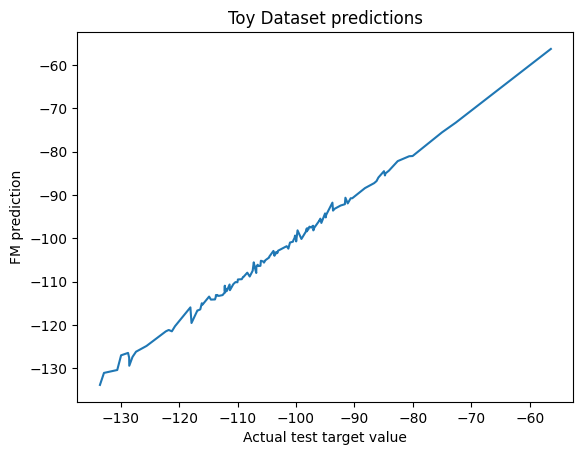

In [ ]:
y_pred = fm.predict(X_test)

sns.lineplot(x=y_test, y=y_pred)
plt.title("Toy Dataset predictions")
plt.xlabel("Actual test target value")
plt.ylabel("FM prediction")


## Movies dataset

MovieLens100k and MovieLens1M can't be used together -- users' ids don't match.

In [ ]:
with duckdb.connect("/home/maria-khanina/mkgit/movies_project/data/database.duckdb", read_only=True) as db_conn:
    ratings_df = db_conn.execute("""
        SELECT *
        FROM ratings INNER JOIN movies USING (movie_id)
    """).df()


In [ ]:
ratings_df.head()

,user_id,movie_id,rating,timestamp,title,genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [ ]:
ratings_df.shape

(1000209, 6)

In [ ]:
ratings_df.isna().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
title        0
genres       0
dtype: int64

In [ ]:
ratings_df["rating"].value_counts().sort_index()

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

In [ ]:
X = ratings_df[["user_id", "movie_id"]]
y = ratings_df["rating"]

In [ ]:
groupby_user = ratings_df.groupby("user_id")
time_range = groupby_user["timestamp"].max() - groupby_user["timestamp"].min()
days_range = time_range / (60 * 60 * 24)

In [ ]:
days_range.min(), days_range.median(), days_range.max()

(np.float64(0.0012268518518518518),
 np.float64(0.04708912037037037),
 np.float64(1032.9605555555556))

In [ ]:
(days_range > 7).mean()

np.float64(0.29751655629139073)

In [ ]:
X_train, X_test, y_train, y_test = per_var_temporal_split(
    X=ratings_df.drop(columns="rating"),
    y=ratings_df["rating"],
    var="user_id",
    time_col="timestamp",
    test_ratio=0.01,
)

In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((986997, 5), (13212, 5), (986997,), (13212,))

In [ ]:
X_train["user_id"].nunique(), X_test["user_id"].nunique()

(6040, 6040)

In [ ]:
(X_train.groupby("user_id")["timestamp"].max() > X_test.groupby("user_id")["timestamp"].min()).sum()

np.int64(0)

In [ ]:
X_val, X_test, y_val, y_test = per_var_temporal_split(
    X_test,
    y_test,
    var="user_id",
    time_col="timestamp",
    test_ratio=0.5,
)

### Average train rating as prediction

In [ ]:
df_train = pd.concat((X_train, y_train), axis="columns")
avg_total = df_train["rating"].mean()
avg_train_ratings = df_train.groupby("movie_id", as_index=False)["rating"].mean()
avg_train_ratings.columns = ["movie_id", "avg_movie_rating"]
df_train = pd.merge(left=df_train, right=avg_train_ratings, on="movie_id")

In [ ]:
df_val = pd.merge(left=X_val, right=avg_train_ratings, on="movie_id", how="left")
df_val["avg_movie_rating"] = df_val["avg_movie_rating"].fillna(avg_total)

In [ ]:
root_mean_squared_error(y_val, df_val["avg_movie_rating"])

0.9538535885401274

### Factorization Machine with only encoded user_id and movie_id as features

In [ ]:
all_users = np.sort(X_train["user_id"].unique())
all_movies = np.sort(X_train["movie_id"].unique())

In [ ]:
base_fm = Pipeline(
    steps=[
        ("encode", OneHotEncoder(
            categories=[all_users, all_movies],
            handle_unknown="ignore",
        )),
        ("predict", FactorizationMachine(
            factors_num=20,
            weights_penalty=0,
            factors_penalty=0,
            batch_size=1000,
            verbose=True,
        ))
    ]
)

In [ ]:
base_search = GridSearchCV(
    estimator=base_fm,
    param_grid={
        "predict__factors_num": [10, 20, 30],
    },
    verbose=100,
    cv=5,
)

In [ ]:
X_val_preprocessed = base_fm[:-1].fit(X_train).transform(X_val)

In [ ]:
base_search.fit(X_train, y_train, predict__eval_set=(X_val_preprocessed, y_val))

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV 1/5; 1/3] START predict__factors_num=10.....................................
Iteration 0, factors num 10, 
factors abs mean: 0.04461378345265375, 
weights abs mean: 0.058499519837113746, 
intercept 3.5294602238396675, validation rmse -0.9886955612837109
Iteration 10, factors num 10, 
factors abs mean: 0.13953516193206267, 
weights abs mean: 0.12176354677106349, 
intercept 3.422574181125895, validation rmse -0.8716360743316794
Iteration 20, factors num 10, 
factors abs mean: 0.15789542076190785, 
weights abs mean: 0.13622764768439227, 
intercept 3.399404828175828, validation rmse -0.8624978602545085
Iteration 30, factors num 10, 
factors abs mean: 0.1683286641522679, 
weights abs mean: 0.14448623472621702, 
intercept 3.385503230562706, validation rmse -0.8579592470272857
[CV 1/5; 1/3] END .....predict__factors_num=10;, score=-0.883 total time=  35.4s
[CV 2/5; 1/3] START predict__factors_num=10...............................

,estimator,Pipeline(step..._penalty=0))])
,param_grid,"{'predict__factors_num': [10, 20, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,100
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,categories,"[array([ 1, ...shape=(6040,)), array([ 1, ...shape=(3704,))]"


In [ ]:
base_search.best_score_

In [ ]:
y_pred = base_search.predict(X_val)

In [ ]:
y_pred = np.clip(y_pred, 1, 5)
root_mean_squared_error(y_val, y_pred)

0.8252098640332654

In [ ]:
base_search.best_params_

{'predict__factors_num': 30}

### Factorization Machine with movies genres added as features

### Factorization Machine with user's preferences added to features

In [ ]:
class UserHistoryTransformer(TransformerMixin, BaseEstimator):
    def __init__(
            self, 
            user_col="user_id",
            item_col="movie_id",
            rating_max=5.0,
    ):
        self.user_col = user_col
        self.item_col = item_col
        self.rating_max = rating_max

    def fit(self, X, y):
        y_scaled = y / self.rating_max
        self._user_history = csr_array(
            (y_scaled, (X[self.user_col], X[self.item_col])),
        )
        return self
    
    def transform(self, X):
        users = X[self.user_col].values
        items = X[self.item_col].values
        
        X_history = self._user_history[users].copy()
        X_history[np.arange(len(X)), items] = 0
        X_history.eliminate_zeros()
        
        return X_history


In [ ]:
transformer = ColumnTransformer(
    transformers=[
        ("extract_history", UserHistoryTransformer(), ["user_id", "movie_id"]),
        (
            "encode", 
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
    verbose=True,
)

In [ ]:
fm_with_history = Pipeline(
    steps=[
        ("transform", transformer),
        ("predict", FactorizationMachine(
            factors_num=20,
            weights_penalty=0.0001,
            factors_penalty=0,
            verbose=True,
        ))
    ],
    verbose=True,
)

In [ ]:
X_val_preprocessed = fm_with_history[:-1].fit(X_train, y_train).transform(X_val)
X_train_transformed = fm_with_history[:-1].transform(X_train)

[ColumnTransformer]  (1 of 2) Processing extract_history, total=  16.2s
[ColumnTransformer] ........ (2 of 2) Processing encode, total=   0.4s
[Pipeline] ......... (step 1 of 1) Processing transform, total= 1.2min


/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


In [ ]:
X_train_transformed[1].toarray()

array([0. , 0.8, 0. , ..., 0. , 0. , 0. ], shape=(13699,))

In [ ]:
fm = FactorizationMachine(
    factors_num=30,
    weights_penalty=0.0001,
    factors_penalty=0,
    verbose=True,
)

fm.fit(X_train_transformed, y_train, eval_set=(X_val_preprocessed, y_val))

Iteration 0, factors num 20, 
factors abs mean: 0.031032048450746315, 
weights abs mean: 0.03577897868777362, 
intercept 3.6142340182094914, validation rmse -0.9768566497701113
Iteration 10, factors num 20, 
factors abs mean: 0.051667945882312945, 
weights abs mean: 0.045268149184148294, 
intercept 3.630918587019413, validation rmse -0.8985645553995996
Iteration 20, factors num 20, 
factors abs mean: 0.060132099808185104, 
weights abs mean: 0.043572193557825205, 
intercept 3.6306346922990045, validation rmse -0.8881344455932326
Iteration 30, factors num 20, 
factors abs mean: 0.06643872966137551, 
weights abs mean: 0.04161957609939305, 
intercept 3.6288046518592068, validation rmse -0.8820921669141994
Iteration 40, factors num 20, 
factors abs mean: 0.07160588508000039, 
weights abs mean: 0.039851837028832444, 
intercept 3.6265097997480376, validation rmse -0.8776964942399587


,factors_num,20
,max_iter,1000
,tol,0.001
,learn_rate,0.01
,loss,<function Fac...x7428c5f40e00>
,dloss_dpred,<function Fac...x7428c5f40b80>
,weights_penalty,0.0001
,factors_penalty,0
,batch_size,1000
,patience,3
,random_state,None


In [ ]:
X_transformed = UserHistoryTransformer().fit(X_train, y_train).transform(X_train)

In [ ]:
row_idx = 239
user_id = X_train.iloc[row_idx]["user_id"]
movie_id = X_train.iloc[row_idx]["movie_id"]
actual_rating = y_train.iloc[row_idx] / 5.0
one_row = X_transformed[row_idx].toarray()
one_row

array([ 854., 2490.,    0., ...,    0.,    0.,    0.], shape=(3955,))

In [ ]:
one_row[2491]

np.float64(0.0)

In [ ]:
np.argmax(one_row[2:])

np.int64(47)

In [ ]:
np.argmax(one_row[2:] == 0.8)

np.int64(1)

In [ ]:
one_row[3]

np.float64(0.8)

In [ ]:
one_row[49]

np.float64(1.0)

In [ ]:
ratings_df[(ratings_df["user_id"] == 854) & (ratings_df["movie_id"] == 47)]

,user_id,movie_id,rating,timestamp,title,genres
87061,854,47,5,975351480,Seven (Se7en) (1995),Crime|Thriller


In [ ]:
ratings_df[(ratings_df["user_id"] == 854) & (ratings_df["movie_id"] == 1)]

,user_id,movie_id,rating,timestamp,title,genres
86621,854,1,4,975352017,Toy Story (1995),Animation|Children's|Comedy


In [ ]:
from sklearn.decomposition import NMF

matr_fact = NMF(init="nndsvd", verbose=100)

user_preferences = pd.pivot_table(
    data=pd.concat((X_train, y_train), axis="columns"),
    index="user_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

for n_components in [10, 20, 30]:
    matr_fact.set_params(n_components=n_components)
    matr_fact.fit(user_preferences)
    


violation: 1.0
violation: 0.46984436132553553
violation: 0.33542485159217583
violation: 0.255204908994595
violation: 0.2078718983641401
violation: 0.1711538611059896
violation: 0.13690930977716465
violation: 0.10986508835732922
violation: 0.09090807784834522
violation: 0.07751446196044251
violation: 0.06815987117422895
violation: 0.06093118870098679
violation: 0.05519357733961368
violation: 0.050231467724940686
violation: 0.045933198935338614
violation: 0.042225512002338116
violation: 0.03901040985285749
violation: 0.036335451433076975
violation: 0.03412104448190159
violation: 0.03218107444059148
violation: 0.03070204755293045
violation: 0.029489824180512905
violation: 0.02860979422820544
violation: 0.02782733212014421
violation: 0.027216161161929445
violation: 0.026688915477659964
violation: 0.026234279178008614
violation: 0.02582610324767275
violation: 0.02543651311617311
violation: 0.02504034595072827
violation: 0.024664245082359256
violation: 0.024181147713487786
violation: 0.02366

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


violation: 1.0
violation: 0.3446507285323105
violation: 0.23728158079989453
violation: 0.18045800445824697
violation: 0.14601381749664502
violation: 0.12206825008903022
violation: 0.10244636279304968
violation: 0.0879636122793854
violation: 0.0776576384642326
violation: 0.0683970747315765
violation: 0.06029560490889021
violation: 0.053699851681339124
violation: 0.04842441133138353
violation: 0.04400968605353678
violation: 0.03994059367705874
violation: 0.03589908663863966
violation: 0.03182750657880653
violation: 0.027906472647210204
violation: 0.02462805353858097
violation: 0.022030085949222688
violation: 0.01998569634476209
violation: 0.01833993861035253
violation: 0.017033688573884095
violation: 0.01613135322995293
violation: 0.015468754160245393
violation: 0.015014569870109953
violation: 0.014664348808164212
violation: 0.014396475579090812
violation: 0.014160169281235046
violation: 0.013985433747590054
violation: 0.013833002590950947
violation: 0.01370311073972466
violation: 0.0135

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(
